In [87]:
import pandas as pd
import numpy as np


In [88]:
df=pd.read_csv(r'C:\Users\matus\Downloads\social_media_engagement_5000.csv')



In [89]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [90]:
# Check/Convert datatype

df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [91]:
# Convert datecolumns to datetime

df['posted_at']=pd.to_datetime(df['posted_at'],format='%d-%m-%Y')

In [92]:
df['posted_at'].dtype

dtype('<M8[us]')

In [93]:
# NumPy arrays for basic array operations

likes_array = np.array(df['likes'].dropna())

print("Likes array:", likes_array)
print("Total likes:", np.sum(likes_array))
print("Average likes:", np.mean(likes_array))
print("Maximum likes:", np.max(likes_array))
print("Minimum likes:", np.min(likes_array))


Likes array: [ 7011. 11750.  4862. ... 13487. 16894. 14830.]
Total likes: 49019162.0
Average likes: 10107.043711340206
Maximum likes: 19998.0
Minimum likes: 10.0


In [94]:
#Task2.1 Detect missing values

df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [95]:
#Task 2.2 Handling numerical values using median 

columns=['age','likes','comments','shares']

for col in columns:
    df[col]=df[col].fillna(df[col].median())

In [96]:
# handling categorical values using mode

cat_columns=['gender','sentiment']

for col in cat_columns:
    df[col]=df[col].fillna(df[col].mode()[0])

In [97]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [98]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [99]:
# Task2.1  Using isna() after cleaning missing values

df.isna().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

After handling missing values using median and mode imputation ,i used isna().sum()to check whether any missing values 
remained in the dataset.
The result showed zero missing values in all columns,confirming that missing values had been handled carefully.


In [100]:
df_copy=pd.read_csv(r'C:\Users\matus\Downloads\social_media_engagement_5000.csv')

I loaded the original dataset again into a separate DataFrame named df_original to demonstrate the remaining missing-value handling methods. 
Since I had already handled missing values using median for numerical columns and mode for categorical columns in my main DataFrame (df),I used df_original to demonstrate other methods such as dropna(), fillna,forward-fill.
This allows me to demonstrate the different techniques without affecting my previously cleaned dataset.

In [101]:
# Handling missing values using dropna

df_drop = df_copy.dropna()

print(df_copy.shape)
print(df_drop.shape)

(5000, 19)
(4162, 19)


In [102]:
# Handling missing values using fillna

df_fill = df_copy.copy()
df_fill['age'] = df_fill['age'].fillna(0)

print(df_fill['age'].isna().sum())

0


In [103]:
# Handling missing values using forward-fill

df_forward = df_copy.copy()
df_forward['likes'] = df_forward['likes'].ffill()

print(df_forward['likes'].isna().sum())

0


After applying these methods, I checked the remaining missing values using isna().sum().
A result of 0 indicates that no missing values remain in the selected column.

### My main DataFrame (df) was already cleaned using median imputation for numerical columns and mode imputation for categorical columns.Therefore, I retained df for the remaining data analysis, calculations, and visualizations.

## Duplicate Handling


In [104]:
# identify and remove duplicates

df.duplicated().sum()

np.int64(0)

I checked for duplicate rows using duplicated().sum().
The result was zero, indicating that no duplicate rows were found in the dataset.


## Dataformatting



In [105]:
df.dtypes




user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

Fix incorrect datatypes

I checked the data types of all columns using df.dtypes. The posted_at column was already converted from string to datetime format.
The remaining columns were checked, and no further conversions were needed because all data types were already appropriate.

In [106]:
# Standardize categories

df['gender'] = df['gender'].str.strip().str.lower()
df['gender'].unique()



<ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: str

The labels are consistent, with no extra spaces or differences in capitalization.

In [107]:
df['sentiment'] = df['sentiment'].str.strip().str.lower()
df['sentiment'].unique()

<ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

The labels are consistent,with no extra spaces or differences in capitalization.


In [108]:
# Correct unrealistic values in likes, comments, shares

cols = ['likes', 'comments', 'shares']

df[cols].describe()

,likes,comments,shares
count,5000.000000,5000.000000,5000.0000
mean,10106.997400,1502.039800,1002.9106
std,5702.293017,856.393312,570.8552
min,10.000000,0.000000,0.0000
25%,5235.000000,792.000000,511.0000
50%,10105.500000,1497.000000,1012.0000
75%,14959.000000,2235.250000,1483.0000
max,19998.000000,2999.000000,1999.0000


In [109]:
cols = ['likes', 'comments', 'shares']

(df[cols] < 0).sum()
df[cols].max()

likes       19998.0
comments     2999.0
shares       1999.0
dtype: float64

In [110]:
Q1 = df[cols].quantile(0.25)
Q3 = df[cols].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[ ((df[cols] < lower) | (df[cols] > upper)).any(axis=1)]

print(outliers[cols])

Empty DataFrame
Columns: [likes, comments, shares]
Index: []


I used describe() to examine the summary statistics and checked
for negative values and maximum values in the likes, comments,
and shares columns. I also applied the IQR method to detect
outliers. No negative values or IQR-based outliers were detected,
so no corrections were required based on these checks.

## Feature Cleaning

In [111]:
# Extract hashtag count

df['hashtag_count'] = df['hashtags'].str.count(r'#\w+')



In [112]:
df[['hashtags', 'hashtag_count']].head(10)




,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [113]:
# clean sentiment labels

df['sentiment'].unique()

<ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

Sentiment labels were already cleaned and standardized in the previous data-cleaning step.

## Data Exploration using Pandas

In [114]:


df.head()


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [115]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [116]:
df.shape

(5000, 20)

In [117]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [118]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [119]:
df.dtypes


user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

In [120]:
df.describe()


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [121]:
# Analyze categorical distributions using value_counts(), unique(), and nunique().

cat_columns = ['gender', 'country', 'post_type', 'post_category',
        'sentiment', 'device_type', 'is_verified']

for cols in cat_columns:
    
    print('\n',cols)
    print('Value_counts:',df[cols].value_counts())
    print('unique values:',df[cols].unique())
    print('nunique values:',df[cols].nunique())
    



 gender
Value_counts: gender
male      1849
other     1581
female    1570
Name: count, dtype: int64
unique values: <ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: str
nunique values: 3

 country
Value_counts: country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
unique values: <ArrowStringArray>
[   'Brazil',        'UK',    'France',    'Canada',     'Japan', 'Australia',
     'India',       'UAE',   'Germany',       'USA']
Length: 10, dtype: str
nunique values: 10

 post_type
Value_counts: post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
unique values: <ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
nunique values: 4

 post_category
Value_counts: post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
trave

In [122]:
# Create a correlation matrix for numerical fields

numeric_fld= df.select_dtypes(include='number')

corr_matrix=numeric_fld.corr()
print(corr_matrix)




                   user_id       age   post_id     likes  comments    shares  \
user_id           1.000000 -0.006688  0.020051  0.025811 -0.033395  0.013763   
age              -0.006688  1.000000 -0.013153 -0.036322 -0.007284  0.013871   
post_id           0.020051 -0.013153  1.000000  0.014526 -0.010540  0.001846   
likes             0.025811 -0.036322  0.014526  1.000000 -0.018421  0.004712   
comments         -0.033395 -0.007284 -0.010540 -0.018421  1.000000  0.006142   
shares            0.013763  0.013871  0.001846  0.004712  0.006142  1.000000   
watch_time_sec   -0.016847  0.005542  0.018374  0.008710 -0.016351  0.014658   
impression_count  0.015326  0.013322 -0.007709  0.007952 -0.009395 -0.005204   
follower_count    0.010124 -0.024894 -0.002844 -0.022982 -0.011733 -0.010783   
engagement_rate  -0.004282  0.008039  0.010139  0.093520  0.000051  0.021724   
hashtag_count    -0.013692  0.007173  0.007344 -0.002190 -0.015230  0.013379   

                  watch_time_sec  impre

In [123]:
# Group by

print(df.groupby('post_type')['likes'].mean())
print('\n')
print(df.groupby('country')['impression_count'].sum())
print('\n')
print(df.groupby('post_category')['comments'].mean())
print('\n')
print(df.groupby('gender')['follower_count'].mean())

            

post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64


country
Australia    23834767
Brazil       24793360
Canada       24984716
France       25656926
Germany      23816649
India        28067377
Japan        23418816
UAE          24610992
UK           25201861
USA          25683200
Name: impression_count, dtype: int64


post_category
education    1455.337559
fashion      1530.540404
fitness      1501.142222
food         1510.876897
lifestyle    1467.840198
music        1558.710236
tech         1505.548872
travel       1485.948333
Name: comments, dtype: float64


gender
female    381623.528025
male      398262.410492
other     400351.036053
Name: follower_count, dtype: float64


## Data Wrangling




Task 4.1 merge,concat or join

Created a copy of the original dataset named df_original for backup and data-cleaning purposes. Since both DataFrames containthe same records, merging or concatenating them was unnecessary.Therefore, I continued the analysis using the cleaned DataFrame.


In [124]:
# create new fields

df['engagement_score']=df['likes']+df['shares']+df['comments']



In [125]:
#4.2-optional

df['log_transformed metrics']=np.log1p(df['likes'])

#4.2

### The hashtag_count feature was already created during feature cleaning,so it was reused without creating it again.

In [126]:
df[['engagement_score', 'log_transformed metrics', 'hashtag_count']].head()




,engagement_score,log_transformed metrics,hashtag_count
0,8522.0,8.855378,3
1,16163.0,9.371694,1
2,6161.0,8.489411,1
3,7482.0,8.585039,3
4,16717.0,9.448018,1


In [127]:
# 4.3 groupby

print(df.groupby('post_type')['engagement_score'].mean())
print('\n')
print(df.groupby('country')['watch_time_sec'].sum())
print('\n')
print(df.groupby('sentiment')['comments'].mean())

post_type
image    12649.390537
reel     12524.031567
text     12613.243775
video    12664.594286
Name: engagement_score, dtype: float64


country
Australia    2046283
Brazil       2040800
Canada       2053896
France       1980403
Germany      1948425
India        2149007
Japan        1830599
UAE          2015935
UK           2030516
USA          1976652
Name: watch_time_sec, dtype: int64


sentiment
negative    1516.094792
neutral     1528.404060
positive    1480.650617
Name: comments, dtype: float64


# Statistical Analysis


In [128]:
# Mean ,Median and Mode

columns=['likes','comments','shares','watch_time_sec','engagement_rate','follower_count']

for col in columns:
    print(f'\nStatistics for {col}:')
    print('Mean:',df[col].mean())
    print('Median:',df[col].median())
    print('Mode:',df[col].mode()[0])
          


Statistics for likes:
Mean: 10106.9974
Median: 10105.5
Mode: 10105.5

Statistics for comments:
Mean: 1502.0398
Median: 1497.0
Mode: 1497.0

Statistics for shares:
Mean: 1002.9106
Median: 1012.0
Mode: 1012.0

Statistics for watch_time_sec:
Mean: 4014.5032
Median: 4034.5
Mode: 916

Statistics for engagement_rate:
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: 0.006362909

Statistics for follower_count:
Mean: 393698.2248
Median: 388982.0
Mode: 497502


The engagement_rate column contains unusually high values that may influence the mean. 
Therefore, average engagement rates should be interpreted cautiously.

In [129]:
# standard deviation & variance

for col in columns:
    print(f'\nStatistics for {col}:')
    print('Standard deviation:',df[col].std())
    print('Variance:',df[col].var())
    


Statistics for likes:
Standard deviation: 5702.293017183877
Variance: 32516145.65382401

Statistics for comments:
Standard deviation: 856.3933120458984
Variance: 733409.5049169434

Statistics for shares:
Standard deviation: 570.8551999758852
Variance: 325875.65933950787

Statistics for watch_time_sec:
Standard deviation: 2308.0964590420845
Variance: 5327309.264242608

Statistics for engagement_rate:
Standard deviation: 5.31802922266154
Variance: 28.281434813082104

Statistics for follower_count:
Standard deviation: 230927.88453461003
Variance: 53327687855.63019


In [130]:
# percentiles

for col in columns:
    print(f'\nPercentiles {col}:')
    print(df[col].quantile([0.25, 0.50, 0.75, 0.90]))


Percentiles likes:
0.25     5235.0
0.50    10105.5
0.75    14959.0
0.90    18016.3
Name: likes, dtype: float64

Percentiles comments:
0.25     792.00
0.50    1497.00
0.75    2235.25
0.90    2695.10
Name: comments, dtype: float64

Percentiles shares:
0.25     511.0
0.50    1012.0
0.75    1483.0
0.90    1795.1
Name: shares, dtype: float64

Percentiles watch_time_sec:
0.25    2017.75
0.50    4034.50
0.75    6020.25
0.90    7212.10
Name: watch_time_sec, dtype: float64

Percentiles engagement_rate:
0.25    0.145781
0.50    0.253896
0.75    0.504794
0.90    1.201200
Name: engagement_rate, dtype: float64

Percentiles follower_count:
0.25    194480.00
0.50    388982.00
0.75    589744.25
0.90    717755.90
Name: follower_count, dtype: float64


## Data Visualization

In [131]:


import matplotlib.pyplot as plt
import seaborn as sns


## Matplotlib Data Visualization

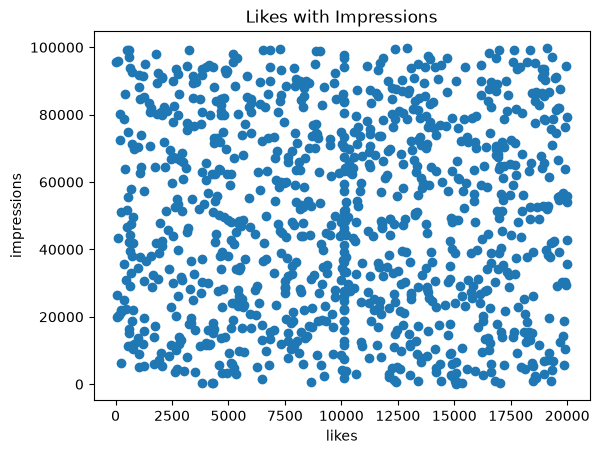

In [132]:
# Scatter plot

sample_df = df.sample(n=1000, random_state=42)

plt.scatter(sample_df['likes'],sample_df['impression_count'])
plt.xlabel('likes')
plt.ylabel('impressions')
plt.title('Likes with Impressions') 
plt.show()




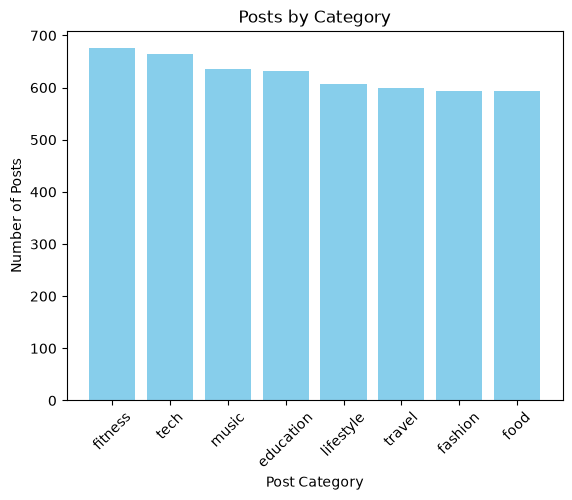

In [133]:
# barchart

post_counts = df['post_category'].value_counts()

plt.bar(post_counts.index, post_counts.values, color='skyblue')
plt.title('Posts by Category')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)
plt.show()


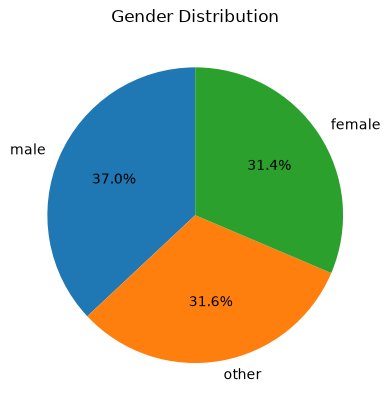

In [134]:
# Piechart

gender_counts = df['gender'].value_counts()

plt.pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',startangle=90)
plt.title('Gender Distribution')
plt.show()

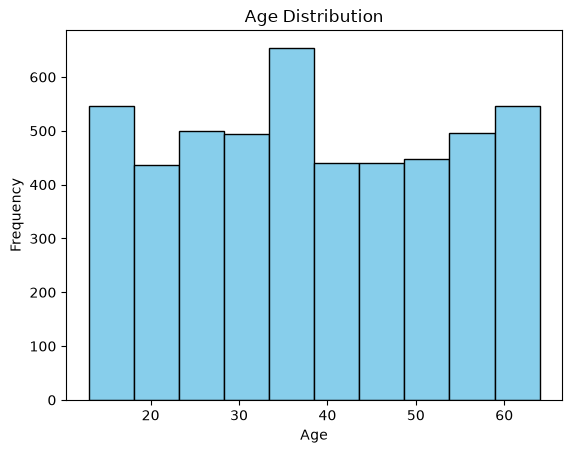

In [135]:
# histogram

plt.hist(df['age'],bins=10,edgecolor='black',color='skyblue')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

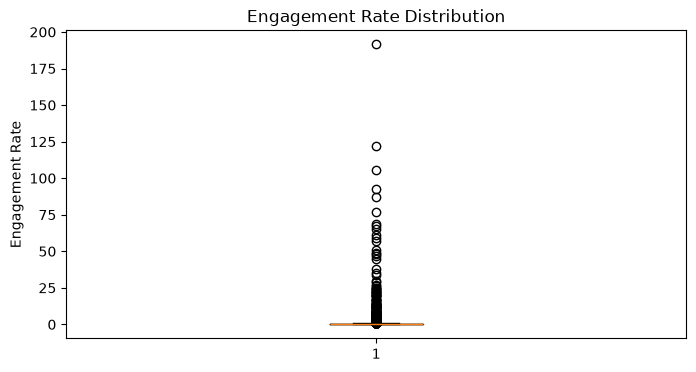

In [136]:
#boxplot

plt.figure(figsize=(8, 4))

plt.boxplot(df['engagement_rate'])

plt.title('Engagement Rate Distribution')
plt.ylabel('Engagement Rate')
plt.show()

# Seaborn Visualization

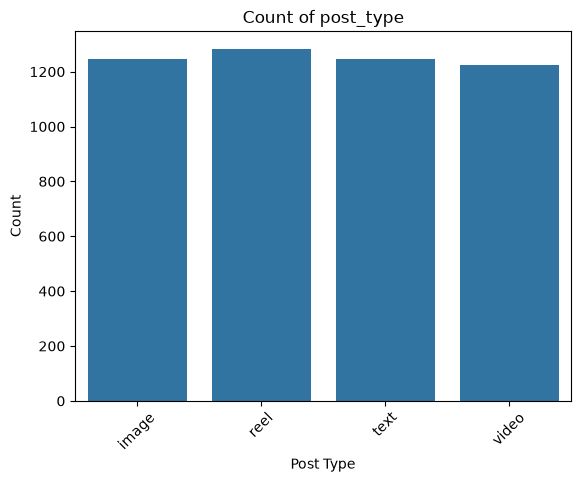

In [137]:
# countplot

sns.countplot(data=df,x='post_type')
plt.title('Count of post_type')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()


           
           



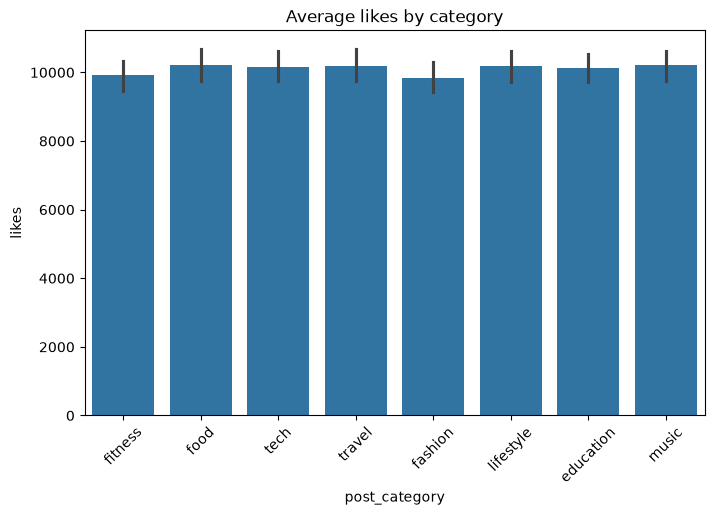

In [138]:
# Barplot

plt.figure(figsize=(8,5))
sns.barplot(data=df,x='post_category',y='likes')
plt.xlabel('post_category')
plt.ylabel('likes')
plt.title('Average likes by category')
plt.xticks(rotation=45)
plt.show()




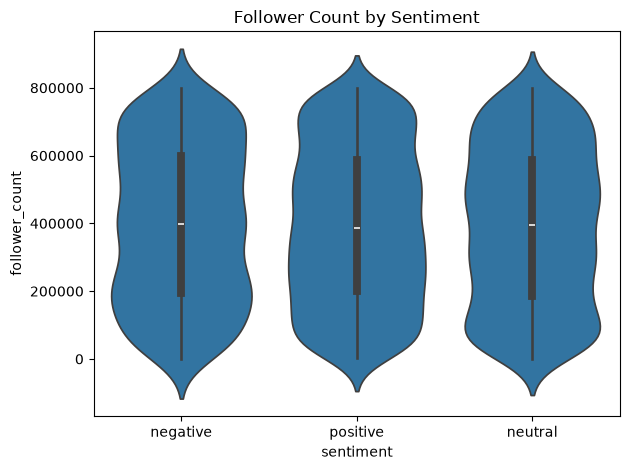

In [139]:
# violin plot

sns.violinplot(data=df, x='sentiment', y='follower_count')
plt.title('Follower Count by Sentiment')
plt.tight_layout()
plt.show()


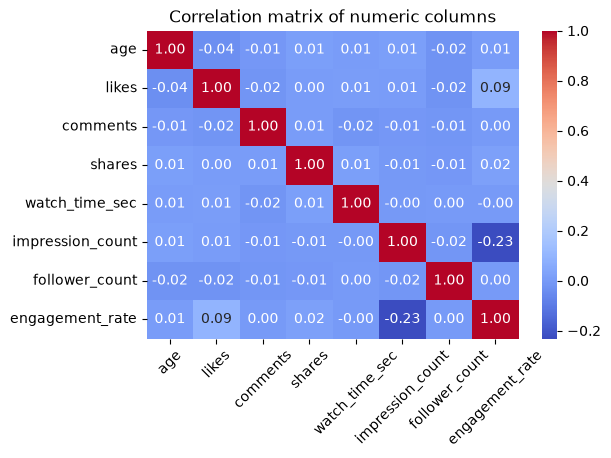

In [140]:
# heatmap

numeric_cols=['age', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'follower_count','engagement_rate']

corr_matrix=df[numeric_cols].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='coolwarm')
plt.title('Correlation matrix of numeric columns')
plt.xticks(rotation=45)
plt.show()



# Plotly

In [141]:
import plotly.express as px

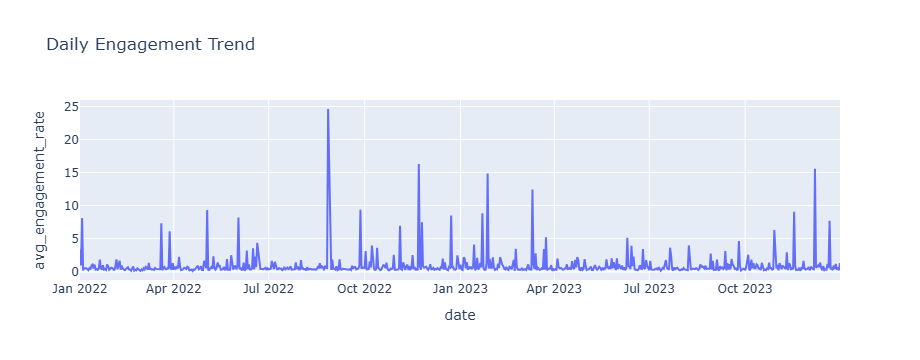

In [142]:
# interactive linechart

daily = df.groupby(df['posted_at'].dt.date)['engagement_rate'].mean().reset_index()
daily.columns = ['date', 'avg_engagement_rate']

fig = px.line(daily, x='date',y='avg_engagement_rate', title='Daily Engagement Trend')

fig.show()


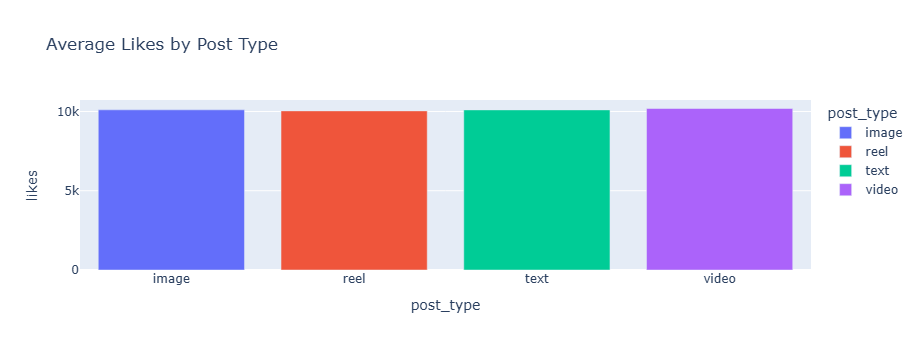

In [143]:
# interactive barchart

avg_likes = df.groupby('post_type',as_index=False)['likes'].mean()

fig = px.bar( avg_likes,x='post_type', y='likes',title='Average Likes by Post Type',color='post_type', width=400,
    height=350)

fig.show()


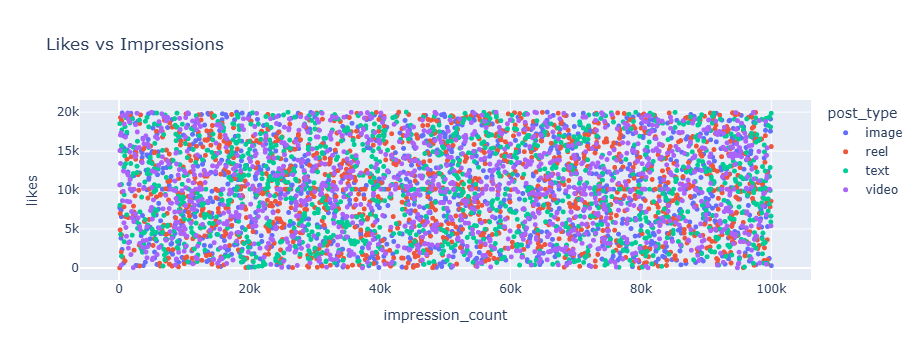

In [144]:
# interactive scatterplot

fig = px.scatter( df, x='impression_count', y='likes', color='post_type', hover_data=['country', 'sentiment'],
    title='Likes vs Impressions')
fig.update_traces(marker_size=5)
fig.show()



# Data Analysis

In [145]:
# Content performance

df.groupby('post_type')['engagement_score'].mean().sort_values(ascending=False)

post_type
video    12664.594286
image    12649.390537
text     12613.243775
reel     12524.031567
Name: engagement_score, dtype: float64

In [146]:
df.groupby('post_category')['engagement_score'].mean().sort_values(ascending=False)

post_category
music        12788.549606
food         12739.200675
tech         12686.490226
travel       12650.559167
lifestyle    12639.539539
education    12578.270206
fitness      12457.791852
fashion      12356.420875
Name: engagement_score, dtype: float64

In [147]:
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

## User Trends

In [148]:
# Age affects engagement

bins = [0, 18, 25, 35, 45, 60, 100]
labels = ['Under 18', '18-25', '26-35', '36-45', '46-60', '60+']

df['age_group'] = pd.cut( df['age'], bins=bins,labels=labels,include_lowest=True)
age_engagement = df.groupby('age_group', observed=False)['engagement_rate'].mean()

print(age_engagement)


age_group
Under 18    0.867038
18-25       1.059536
26-35       0.865316
36-45       0.860741
46-60       1.152669
60+         0.801381
Name: engagement_rate, dtype: float64


In [149]:
# performance difference for verified accounts

verified_performance = df.groupby('is_verified')[['engagement_rate','likes','watch_time_sec']].mean()

print(verified_performance)

             engagement_rate         likes  watch_time_sec
is_verified                                               
False               0.954744  10137.201129     4005.201240
True                1.054250   9824.533126     4101.494824


## Behavioural insights




In [150]:
df['hour']=df['posted_at'].dt.hour

hourly_impressions=df.groupby('hour')['impression_count'].mean().sort_values(ascending=False)
print(hourly_impressions)


hour
0    50013.7328
Name: impression_count, dtype: float64


The posted_at column contains dates but does not provide actual posting times. 
All 5,000 records show hour 0 because the timestamps are recorded at midnight.
Therefore, the best time of day for impressions cannot be determined from this dataset.

In [151]:

device_watch_time=df.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

print(device_watch_time)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64


# Sentiment analysis

In [152]:
sentiment_performance=df.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)

print(sentiment_performance)

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64


In [153]:
sentiment_behavior=df.groupby('sentiment')[['likes', 'comments', 'shares', 'engagement_rate']].mean()

print(sentiment_behavior)


                  likes     comments       shares  engagement_rate
sentiment                                                         
negative   10208.096875  1516.094792  1007.307292         1.038486
neutral     9923.194499  1528.404060   996.565160         0.991170
positive   10180.062077  1480.650617  1005.086749         0.919744


In [154]:
df['sentiment'].value_counts()

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64

## Final Insights and Conclusion – Social Media Engagement Analytics

### 1.Content Performance

- Best-performing post type: Video posts recorded the highest average engagement score, while reels recorded the lowest.
- Best-performing content category: Music had the highest average engagement score, followed by food and technology. Fashion had the lowest score.
- Country performance: Brazil recorded the highest average engagement rate (1.54), followed by Australia (1.32) and France (1.15). The USA recorded the lowest average 
  engagement rate (0.58).
      
### 2.User Trends

- Age and engagement: Users aged 46–60 had the highest average engagement rate (1.15), followed by users aged 18–25 (1.06). Users aged 60+ had the lowest rate (0.80).
- Verified accounts: Verified accounts had a higher average engagement rate (1.05) and watch time than non-verified accounts. However, non-verified accounts received more average likes.

### 3. Behavioral Insights

- Best time of day for impressions: This could not be determined because the dataset contains dates but no actual posting times. All 5,000 records were assigned hour 0.
- Device type and watch time:Mobile users had the highest average watch time (4,087.83 seconds), followed by tablet users (3,979.74 seconds) and desktop users (3,974.79 seconds).

### 4. Sentiment Analysis
    
- Best-performing sentiment: Negative posts had the highest average engagement rate (1.04), followed by neutral posts (0.99) and positive posts (0.92).
- Negative and neutral post behavior: Negative posts received the highest average likes and shares, while neutral posts received the highest average comments. Positive posts were the most common, with 2,513 posts.

### Conclusion
    
The analysis shows that video posts and music-related content achieved the highest average engagement scores. Brazil had the highest average engagement rate among the countries analyzed, and users aged 46–60 showed the highest average engagement rate among age groups.
Verified accounts performed better in average engagement rate and watch time, while mobile users recorded the highest average watch time. Negative posts showed a higher average engagement rate than positive posts.
These findings describe patterns in the available dataset and do not necessarily establish cause-and-effect relationships.

### Limitation

The dataset does not include actual posting times, so the best time of day for impressions could not be identified. The engagement-rate results should also be interpreted cautiously because some unusually high values may affect averages.
    